# Projeto de Bloco: Sistema de Atendimento com IA
## Trabalho Prático 1: Análise Exploratória de Dados (EDA)

**Aluno:** Grazielli Soares Pereira  
**Curso:** Engenharia de software
**Professor:** Tiago Xavier  

---
### 1. Documentação Técnica do Dataset
* **a. Fonte:** *Customer Support Ticket Dataset*, disponível publicamente na plataforma Kaggle.
* **b. Principais Características:** Trata-se de um conjunto de dados tabulares que simula interações de suporte ao cliente. Possui variáveis estruturadas (como IDs, status, prioridade, canal de suporte, satisfação) e não estruturadas (como descrições dos tickets e comentários).
* **c. Motivo da Escolha:** Oferece uma combinação ideal de texto livre (descrição do problema do cliente) com categorias rotuladas de atendimento, permitindo o treinamento futuro de modelos de Processamento de Linguagem Natural (NLP) e classificação de intenções em um chatbot.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações esteticas dos graficos
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')
%matplotlib inline

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### 2. Análise Exploratória de Dados (EDA)

#### a. Compreensão do Problema e do Dataset
O objetivo desta análise é explorar o dataset de suporte ao cliente para identificar padrões de comportamento, os problemas mais frequentes e as intenções dos usuários. Essa compreensão orientará a criação de uma API inteligente capaz de classificar chamados automaticamente

In [3]:
# Inspeção Inicial dos Dados
# Carregamento do arquivo CSV a partir do diretório data
df = pd.read_csv('../data/customer_support_tickets.csv')

print("--- Formato dos Dados (Linhas, Colunas) ---")
print(df.shape)

print("\n--- Primeiras 5 Linhas ---")
df.head()

--- Formato dos Dados (Linhas, Colunas) ---
(8469, 17)

--- Primeiras 5 Linhas ---


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [4]:
# Inspeção de tipos de dados e memória utilizada
print("--- Informações do DataFrame ---")
df.info()

print("\n--- Estatísticas Descritivas (Variáveis Numéricas) ---")
df.describe()

--- Informações do DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   object 
 2   Customer Email                8469 non-null   object 
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   object 
 5   Product Purchased             8469 non-null   object 
 6   Date of Purchase              8469 non-null   object 
 7   Ticket Type                   8469 non-null   object 
 8   Ticket Subject                8469 non-null   object 
 9   Ticket Description            8469 non-null   object 
 10  Ticket Status                 8469 non-null   object 
 11  Resolution                    2769 non-null   object 
 12  Ticket Priority              

,Ticket ID,Customer Age,Customer Satisfaction Rating
count,8469.000000,8469.000000,2769.000000
mean,4235.000000,44.026804,2.991333
std,2444.934048,15.296112,1.407016
min,1.000000,18.000000,1.000000
25%,2118.000000,31.000000,2.000000
50%,4235.000000,44.000000,3.000000
75%,6352.000000,57.000000,4.000000
max,8469.000000,70.000000,5.000000


In [5]:

# Inspeção das variáveis categóricas e textuais
print("--- Estatísticas das Variáveis Categóricas ---")
display(df.describe(include=['object']))

print("\n--- Colunas do Dataset ---")
for coluna in df.columns:
    print(f"{coluna}: {df[coluna].dtype}")

print("\n--- Quantidade de Valores Únicos ---")
display(df.nunique().sort_values(ascending=False))


--- Estatísticas das Variáveis Categóricas ---


,Customer Name,Customer Email,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution
count,8469,8469,8469,8469,8469,8469,8469,8469,8469,2769,8469,8469,5650,2769
unique,8028,8320,3,42,730,5,16,8077,3,2769,4,4,5470,2728
top,Michael Garcia,asmith@example.com,Male,Canon EOS,2020-10-21,Refund request,Refund request,I'm having an issue with the {product_purchase...,Pending Customer Response,Case maybe show recently my computer follow.,Medium,Email,2023-06-01 20:45:39,2023-06-01 17:14:42
freq,5,4,2896,240,24,1752,576,25,2881,1,2192,2143,3,3



--- Colunas do Dataset ---
Ticket ID: int64
Customer Name: object
Customer Email: object
Customer Age: int64
Customer Gender: object
Product Purchased: object
Date of Purchase: object
Ticket Type: object
Ticket Subject: object
Ticket Description: object
Ticket Status: object
Resolution: object
Ticket Priority: object
Ticket Channel: object
First Response Time: object
Time to Resolution: object
Customer Satisfaction Rating: float64

--- Quantidade de Valores Únicos ---


Ticket ID                       8469
Customer Email                  8320
Ticket Description              8077
Customer Name                   8028
First Response Time             5470
Resolution                      2769
Time to Resolution              2728
Date of Purchase                 730
Customer Age                      53
Product Purchased                 42
Ticket Subject                    16
Customer Satisfaction Rating       5
Ticket Type                        5
Ticket Channel                     4
Ticket Priority                    4
Customer Gender                    3
Ticket Status                      3
dtype: int64

#### c. Verificação da Qualidade dos Dados
Nesta etapa, verificaremos a presença de valores ausentes (nulos) e registros duplicados no dataset

In [6]:

# 1.3 - Verificação da Qualidade dos Dados

print("--- Valores Ausentes por Coluna ---")

qualidade = pd.DataFrame({
    "Valores Ausentes": df.isnull().sum(),
    "Percentual (%)": (df.isnull().mean() * 100).round(2)
})

display(qualidade.sort_values(
    by="Percentual (%)",
    ascending=False
))

print("\n--- Registros Duplicados ---")
duplicados = df.duplicated().sum()
print(f"Total de registros duplicados: {duplicados}")

print("\n--- IDs Duplicados ---")
print(df["Ticket ID"].duplicated().sum())

print("\n--- Valores Inválidos de Idade ---")
print(df[
    (df["Customer Age"] < 0) |
    (df["Customer Age"] > 120)
].shape[0])

print("\n--- Avaliações Fora da Escala de 1 a 5 ---")
avaliacoes_invalidas = df[
    df["Customer Satisfaction Rating"].notna() &
    ~df["Customer Satisfaction Rating"].between(1, 5)
]

print(len(avaliacoes_invalidas))


--- Valores Ausentes por Coluna ---


,Valores Ausentes,Percentual (%)
Customer Satisfaction Rating,5700,67.30
Resolution,5700,67.30
Time to Resolution,5700,67.30
First Response Time,2819,33.29
Ticket ID,0,0.00
Customer Name,0,0.00
Customer Email,0,0.00
Customer Age,0,0.00
Customer Gender,0,0.00
Ticket Subject,0,0.00



--- Registros Duplicados ---
Total de registros duplicados: 0

--- IDs Duplicados ---
0

--- Valores Inválidos de Idade ---
0

--- Avaliações Fora da Escala de 1 a 5 ---
0


#### d. Limpeza e Preparação dos Dados
Tratamento de colunas de datas para o formato adequado (`datetime`) e remoção/imputação de valores nulos se necessário.

In [ ]:

# 1.4 - Limpeza e Preparação dos Dados

# Remover duplicatas, caso existam
df = df.drop_duplicates().copy()

# Converter colunas de datas
colunas_data = [
    "Date of Purchase",
    "First Response Time",
    "Time to Resolution"
]

for coluna in colunas_data:
    df[coluna] = pd.to_datetime(df[coluna], errors="coerce")

# Padronizar espaços em variáveis categóricas
colunas_categoricas = [
    "Customer Gender",
    "Product Purchased",
    "Ticket Type",
    "Ticket Subject",
    "Ticket Status",
    "Ticket Priority",
    "Ticket Channel"
]

for coluna in colunas_categoricas:
    df[coluna] = df[coluna].str.strip()

# Criar variável numérica para análise textual
df["Description Length"] = (
    df["Ticket Description"].fillna("").str.len()
)

# Preservar os valores ausentes originais
# em satisfação, resolução e tempos de atendimento

print("--- Tipos de Dados Após Preparação ---")
print(df[colunas_data].dtypes)

print("\n--- Estatísticas do Tamanho das Descrições ---")
display(df["Description Length"].describe())

print("\nLimpeza e preparação concluidas!")


--- Tipos de Dados Após Preparação ---
Date of Purchase       datetime64[ns]
First Response Time    datetime64[ns]
Time to Resolution     datetime64[ns]
dtype: object

--- Estatísticas do Tamanho das Descrições ---


count    8469.000000
mean      289.821939
std        43.593954
min       151.000000
25%       273.000000
50%       298.000000
75%       318.000000
max       397.000000
Name: Description Length, dtype: float64


Limpeza e preparação concluídas!


#### e. Análise Univariada
Análise da distribuição individual das principais variáveis categóricas e numéricas do dataset.

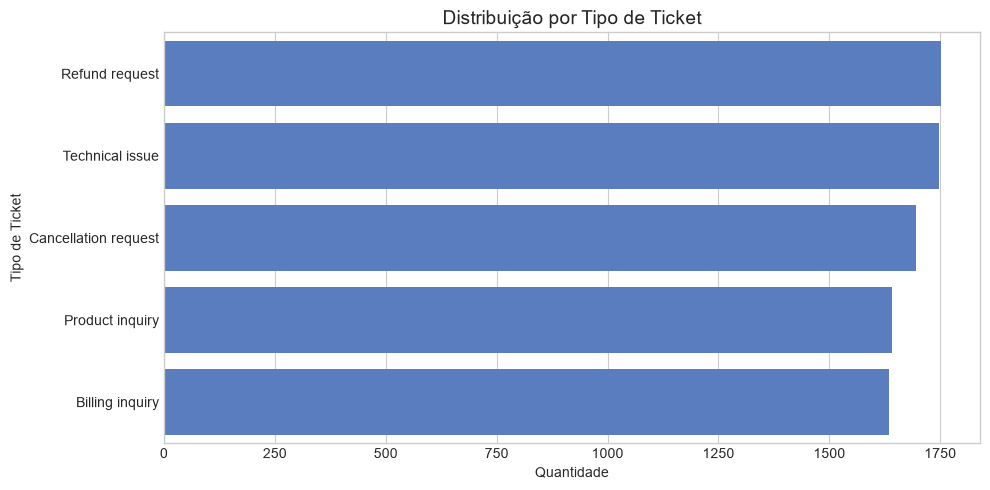

In [ ]:
# Gráfico 1: Distribuição dos tipos de icket ou Categorias
plt.figure(figsize=(10, 5))
if 'Ticket Type' in df.columns:
    sns.countplot(y='Ticket Type', data=df, order=df['Ticket Type'].value_counts().index)
    plt.title('Distribuição por Tipo de Ticket', fontsize=14)
    plt.xlabel('Quantidade')
    plt.ylabel('Tipo de Ticket')
elif 'Ticket Subject' in df.columns:
    sns.countplot(y='Ticket Subject', data=df, order=df['Ticket Subject'].value_counts().index)
    plt.title('Distribuição por Assunto do Ticket', fontsize=14)
plt.tight_layout()
plt.show()

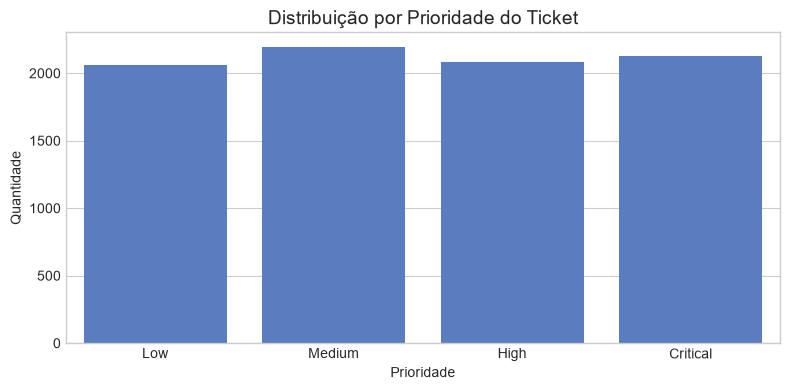

In [7]:
# Gráfico 2: distribuição por prioridade do ticket
plt.figure(figsize=(8, 4))
if 'Ticket Priority' in df.columns:
    sns.countplot(x='Ticket Priority', data=df, order=['Low', 'Medium', 'High', 'Critical'])
    plt.title('Distribuição por Prioridade do Ticket', fontsize=14)
    plt.xlabel('Prioridade')
    plt.ylabel('Quantidade')
    plt.tight_layout()
    plt.show()

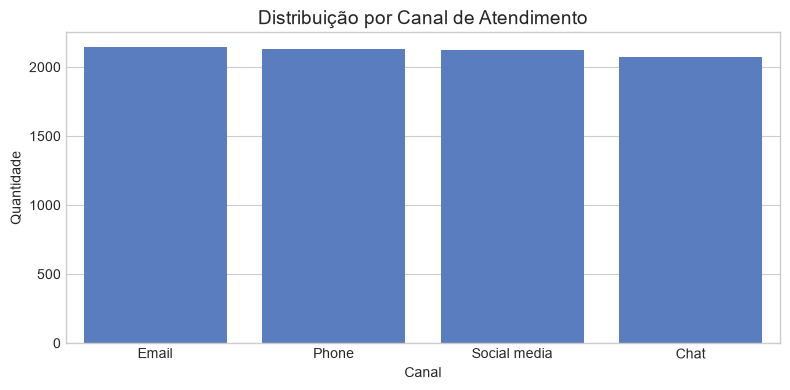

In [8]:
# Gráfico 3: Distribuição por canal de atendimento (ticket channel)
plt.figure(figsize=(8, 4))
if 'Ticket Channel' in df.columns:
    sns.countplot(x='Ticket Channel', data=df, order=df['Ticket Channel'].value_counts().index)
    plt.title('Distribuição por Canal de Atendimento', fontsize=14)
    plt.xlabel('Canal')
    plt.ylabel('Quantidade')
    plt.tight_layout()
    plt.show()

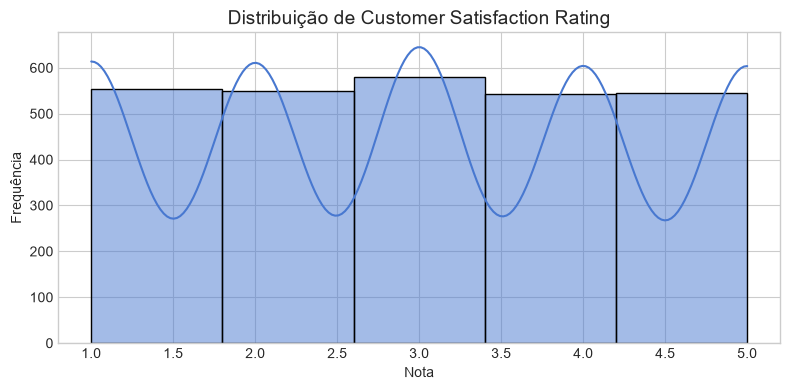

In [9]:
# Gráfico 4: Distribuição das avaliações de satisfação (customer satisfaction / rating)
rating_col = [col for col in df.columns if 'satisfaction' in col.lower() or 'rating' in col.lower()]

if rating_col:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[rating_col[0]].dropna(), kde=True, bins=5)
    plt.title(f'Distribuição de {rating_col[0]}', fontsize=14)
    plt.xlabel('Nota')
    plt.ylabel('Frequência')
    plt.tight_layout()
    plt.show()

### 3. Hipóteses sobre as intenções dos usuarios (exercicio 3)

A partir da análise das distribuições univariadas e dos padrões identificados visualmente nos dados, foi formulado as seguintes **3 hipóteses sobre as intenções dos usuários**:

1. **Hipótese 1 (Predomínio de dúvidas operacionais/cobranças):**  
   *A maior concentração de chamados em categorias como "Billing" (cobrança) ou "Technical Issue" indica que a intenção primária da maioria dos usuários não é o cancelamento do serviço, mas sim a resolução rápida de divergências de faturamento ou problemas de acesso imediato.*

2. **Hipótese 2 (Urgência relacionada ao canal de atendimento):**  
   *Usuários com intenção de resolver problemas "Críticos" ou "Urgentes" tendem a priorizar canais de atendimento síncronos (como Chat ao vivo) em comparação a e-mails. Isso sugere que o agente de IA deve priorizar rotas de alta prioridade para mensagens vindas do canal de chat.*

3. **Hipótese 3 (Satisfação vinculada ao tempo de resposta e categoria):**  
   *A baixa variação nas notas de satisfação em determinadas categorias sugere que certas intenções repetitivas (como redefinição de senha ou consulta de status) podem ser automatizadas via IA com alta aceitação do usuário, reduzindo a fila de suporte humano.*

--- Estatísticas Descritivas ---


,Customer Age,Customer Satisfaction Rating,Description Length
count,8469.000000,2769.000000,8469.000000
mean,44.026804,2.991333,289.821939
std,15.296112,1.407016,43.593954
min,18.000000,1.000000,151.000000
25%,31.000000,2.000000,273.000000
50%,44.000000,3.000000,298.000000
75%,57.000000,4.000000,318.000000
max,70.000000,5.000000,397.000000


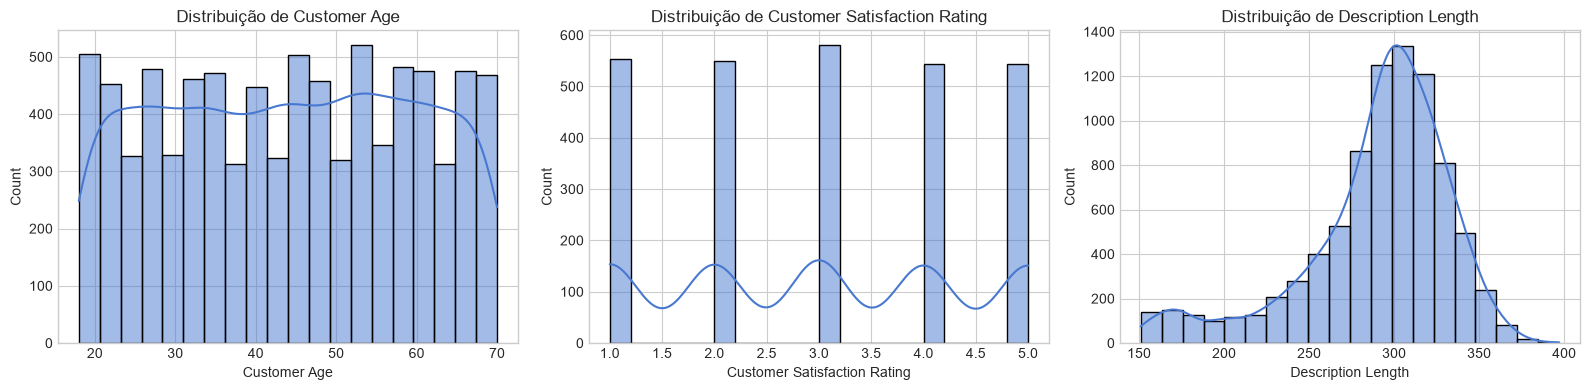

In [ ]:

# 1.5 - Análise univariada das variáveis numéricas

colunas_numericas = [
    "Customer Age",
    "Customer Satisfaction Rating",
    "Description Length"
]

print("--- Estatísticas Descritivas ---")
display(df[colunas_numericas].describe())

# Histogramas das variáveis numéricas
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, coluna in enumerate(colunas_numericas):
    sns.histplot(
        data=df,
        x=coluna,
        bins=20,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribuição de {coluna}")

plt.tight_layout()
plt.show()


#### f. Análise Multivariada
Nesta etapa, serão investigadas as relações entre variáveis numéricas e categóricas, utilizando correlações, visualizações e testes estatísticos.

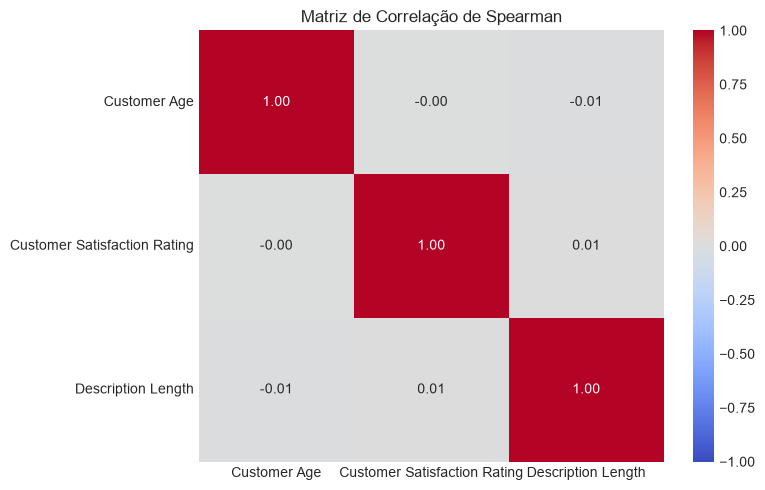

--- Matriz de Correlação ---


,Customer Age,Customer Satisfaction Rating,Description Length
Customer Age,1.000000,-0.004045,-0.013250
Customer Satisfaction Rating,-0.004045,1.000000,0.005565
Description Length,-0.013250,0.005565,1.000000


In [9]:

# 1.6 - Correlação entre variáveis numéricas

colunas_numericas = [
    "Customer Age",
    "Customer Satisfaction Rating",
    "Description Length"
]

correlacao = df[colunas_numericas].corr(method="spearman")

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação de Spearman")
plt.tight_layout()
plt.show()

print("--- Matriz de Correlação ---")
display(correlacao)


In [ ]:

# 1.6 - Testes de hipóteses: Mann-Whitney

from scipy.stats import mannwhitneyu

def testar_hipotese(grupo1, grupo2, nome1, nome2):
    grupo1 = grupo1.dropna()
    grupo2 = grupo2.dropna()

    if len(grupo1) == 0 or len(grupo2) == 0:
        print("Dados insuficientes para realizar o teste.")
        return

    estatistica, p_valor = mannwhitneyu(
        grupo1, grupo2, alternative="two-sided"
    )

    print(f"\nComparação: {nome1} x {nome2}")
    print(f"Amostras: {len(grupo1)} e {len(grupo2)}")
    print(f"Medianas: {grupo1.median():.2f} e {grupo2.median():.2f}")
    print(f"Estatística U: {estatistica:.2f}")
    print(f"Valor-p: {p_valor:.6f}")

    if p_valor < 0.05:
        print("Resultado: rejeitamos H0 (diferença estatisticamente significativa).")
    else:
        print("Resultado: não rejeitamos H0 (sem evidência suficiente de diferença).")


# Hipótese 1: Satisfação por prioridade
print("HIPÓTESE 1 - SATISFAÇÃO E PRIORIDADE")

alta = df.loc[
    df["Ticket Priority"] == "High",
    "Customer Satisfaction Rating"
]

baixa = df.loc[
    df["Ticket Priority"] == "Low",
    "Customer Satisfaction Rating"
]

testar_hipotese(alta, baixa, "High", "Low")


# Hipótese 2: Tamanho da descrição por canal
print("\nHIPÓTESE 2 - DESCRIÇÃO E CANAL")

email = df.loc[
    df["Ticket Channel"] == "Email",
    "Description Length"
]

chat = df.loc[
    df["Ticket Channel"] == "Chat",
    "Description Length"
]

testar_hipotese(email, chat, "Email", "Chat")


HIPÓTESE 1 - SATISFAÇÃO E PRIORIDADE

Comparação: High x Low
Amostras: 705 e 644
Medianas: 3.00 e 3.00
Estatística U: 220739.50
Valor-p: 0.370563
Resultado: não rejeitamos H0 (sem evidência suficiente de diferença).

HIPÓTESE 2 - DESCRIÇÃO E CANAL

Comparação: Email x Chat
Amostras: 2143 e 2073
Medianas: 297.00 e 298.00
Estatística U: 2198908.50
Valor-p: 0.572288
Resultado: não rejeitamos H0 (sem evidência suficiente de diferença).


#### g. Identificação de outliers e anomalias

Nesta etapa, utilizei o método do intervalo interquartil (IQR) para identificar valores atípicos nas variáveis numéricas.
Os resultados serão analisados antes de qualquer decisão sobre remoção de registros.


--- Customer Age ---
Limite inferior: -8.00
Limite superior: 96.00
Quantidade de outliers: 0
Percentual: 0.00%


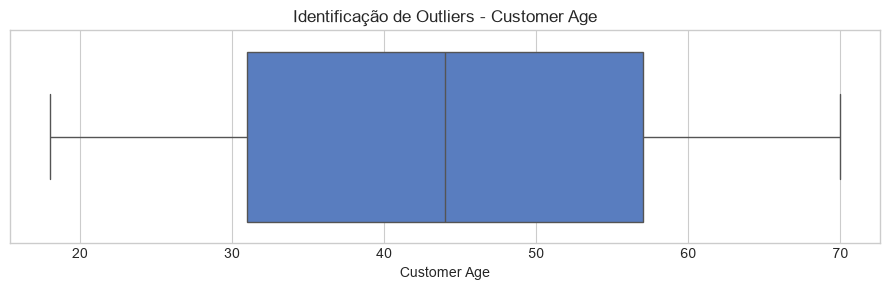


--- Description Length ---
Limite inferior: 205.50
Limite superior: 385.50
Quantidade de outliers: 579
Percentual: 6.84%


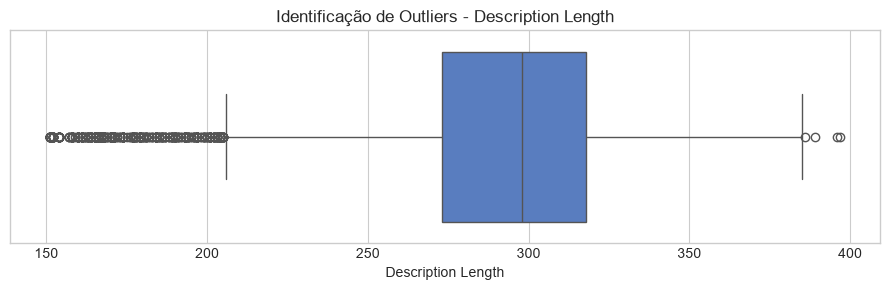

In [ ]:

# 1.7 - Identificação de outliers pelo método IQR

colunas_outliers = [
    "Customer Age",
    "Description Length"
]

for coluna in colunas_outliers:
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    ]

    print(f"\n--- {coluna} ---")
    print(f"Limite inferior: {limite_inferior:.2f}")
    print(f"Limite superior: {limite_superior:.2f}")
    print(f"Quantidade de outliers: {len(outliers)}")
    print(f"Percentual: {len(outliers) / len(df) * 100:.2f}%")

    plt.figure(figsize=(9, 3))
    sns.boxplot(x=df[coluna])
    plt.title(f"Identificação de Outliers - {coluna}")
    plt.tight_layout()
    plt.show()


### 1.8. Documentação do EDA e conclusões

#### Objetivo da análise

A análise exploratória de dados teve como objetivo compreender as características do *Customer Support Ticket Dataset*, identificar padrões de atendimento, avaliar a qualidade dos dados e investigar possíveis relações entre variáveis numéricas, categóricas e textuais.

#### Qualidade e preparação dos dados

O dataset contém 8.469 registros de atendimento e 17 variáveis originais.

Não foram identificados registros duplicados, IDs repetidos, idades inválidas ou avaliações de satisfação fora da escala de 1 a 5.

Foram encontrados valores ausentes nas seguintes variáveis:

- Customer Satisfaction Rating: 67,30%.
- Resolution: 67,30%.
- Time to Resolution: 67,30%.
- First Response Time: 33,29%.

Os valores ausentes foram preservados para evitar a introdução de informações artificiais.

As variáveis de data foram convertidas para o formato datetime, as categorias tiveram seus espaços padronizados e foi criada a variável `Description Length`, representando a quantidade de caracteres das descrições.

#### Análise das variáveis

A análise univariada permitiu visualizar a distribuição dos tipos de chamados, prioridades, canais de atendimento, avaliações de satisfação, idades e tamanhos das descrições.

As descrições possuem média aproximada de 290 caracteres, variando de 151 a 397 caracteres.

Na análise multivariada, as correlações de Spearman entre idade, satisfação e tamanho das descrições ficaram próximas de zero, não indicando associações monotônicas relevantes.

#### Testes de hipóteses

Foi adotado nível de significância de 5% (α = 0,05), utilizando o teste não paramétrico de Mann-Whitney para comparar dois grupos independentes.

**Hipótese 1 — Satisfação e prioridade**

- H₀: as distribuições de satisfação dos tickets de prioridade High e Low não diferem.
- H₁: as distribuições de satisfação diferem entre os grupos.
- Valor-p: 0,370563.
- Mediana dos dois grupos: 3.

Como o valor-p foi superior a 0,05, não rejeitamos H₀. Não foram encontradas evidências estatísticas suficientes de diferença entre os grupos analisados.

**Hipótese 2 — Tamanho da descrição e canal**

- H₀: as distribuições do tamanho das descrições nos canais Email e Chat não diferem.
- H₁: as distribuições diferem entre os canais.
- Valor-p: 0,572288.
- Medianas: 297 caracteres (Email) e 298 caracteres (Chat).

Como o valor-p foi superior a 0,05, não rejeitamos H₀. Não foram encontradas evidências estatísticas suficientes de diferença entre os canais analisados.

#### Identificação de outliers

Foi utilizado o método do intervalo interquartil (IQR).

Na variável Customer Age, nenhum registro foi identificado como outlier.

Na variável Description Length, foram identificados 579 registros atípicos, correspondentes a 6,84% do dataset.

Esses registros foram preservados, pois diferenças no tamanho das descrições podem representar características legítimas das solicitações de suporte.

#### Conclusão geral

 A análise exploratória permitiu compreender a estrutura e as principais características do dataset, além de identificar limitações importantes relacionadas à ausência de informações de satisfação e resolução.

Os testes estatísticos realizados não identificaram diferenças significativas nas duas comparações investigadas, enquanto a análise de correlação revelou associações monotônicas muito fracas entre as variáveis numéricas selecionadas.

Os resultados fornecem uma base para futuras etapas de processamento de linguagem natural, classificação de intenções e desenvolvimento de funcionalidades inteligentes para o atendimento ao cliente.